# 02. Профилирование и очистка данных

**ЛР 2, шаг 7.** Цель: понять, насколько данные пригодны для ответа на вопросы заказчика, найти проблемы и подготовить очищенные слои в `data/processed/`.

Что проверяем по каждому слою:
- число объектов и типы геометрии;
- систему координат (CRS) и охват;
- пустые и некорректные геометрии;
- дубликаты (по идентификатору и по положению);
- заполненность атрибутов;
- объекты за пределами территории.

Найденные проблемы оформляйте задачами с меткой `data` и переносите выводы в `docs/data-quality.md`.\n\n[![Открыть в Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OWNER/REPO/blob/main/notebooks/02_data_profiling.ipynb)\n\nЧтобы кнопка открывала ваш ноутбук, замените в ссылке `OWNER/REPO` на владельца и имя своего репозитория (например, `ivan-p/pm-lab-00-aquamap`). Другие способы открыть ноутбук описаны в приложении Б.

## Настройка среды

Ноутбук рассчитан на **Google Colab** (как получить бесплатный доступ: приложение Б к заданию ЛР 2). Он работает и локально, в Jupyter или VS Code.

Что делает ячейка ниже:
1. В Colab ставит недостающие библиотеки и подключает Google Диск. Colab попросит разрешение на доступ к Диску: выберите тот же аккаунт Google, под которым открыт Colab.
2. Находит рабочую папку группы на Диске. Все данные и результаты сохраняются туда, поэтому после отключения сессии ничего не пропадёт.
3. Создаёт внутри неё ту же структуру папок, что и в репозитории: `data/raw`, `data/manual`, `data/processed`, `docs/img`, `docs/maps`.

**Перед первым запуском** впишите в `PROJECT_FOLDER` имя папки группы на Google Диске.

Запуск всего ноутбука: **Среда выполнения → Выполнить все** (Runtime → Run all).

In [1]:
# === Настройка среды: запустите эту ячейку первой ===
import sys, subprocess
from pathlib import Path

# Имя папки группы в «Моём диске» Google. Обычно совпадает с именем репозитория.
PROJECT_FOLDER = "pm-lab-8-ForestFireMonitoring"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'geopandas>=1.0'], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive") / PROJECT_FOLDER
    if not BASE.exists():
        raise FileNotFoundError(
            f"На Google Диске нет папки «{PROJECT_FOLDER}». Создайте её или добавьте ярлык "
            "общей папки группы в «Мой диск» (приложение Б, шаг 2) и запустите ячейку снова.")
else:
    BASE = Path("..")   # локальный запуск из папки notebooks/ репозитория

RAW, MANUAL, PROCESSED = BASE / "data" / "raw", BASE / "data" / "manual", BASE / "data" / "processed"
IMG, MAPS = BASE / "docs" / "img", BASE / "docs" / "maps"
for folder in (RAW, MANUAL, PROCESSED, IMG, MAPS):
    folder.mkdir(parents=True, exist_ok=True)
print("Среда:", "Google Colab" if IN_COLAB else "локальная", "· рабочая папка:", BASE.resolve())

Mounted at /content/drive
Среда: Google Colab · рабочая папка: /content/drive/.shortcut-targets-by-id/1cv2sPvFAm2CzwRrAGa7DfTvZQblmDOXv/pm-lab-8-ForestFireMonitoring


In [2]:
import geopandas as gpd
import pandas as pd

LAYERS = ["districts", "forests", "cameras", "settlements"]
DUPLICATE_DISTANCE_M = 50

districts = gpd.read_file(RAW / "districts.gpkg")
boundary = districts.union_all()
boundary_gdf = gpd.GeoDataFrame(geometry=[boundary], crs=districts.crs)
layers = {name: gpd.read_file(RAW / f"{name}.gpkg") for name in LAYERS}
METRIC_CRS = boundary_gdf.estimate_utm_crs()
print("Метрическая СК:", METRIC_CRS)

Метрическая СК: EPSG:32640


## Сводный профиль слоёв

In [3]:
def profile(name, gdf):
    g = gdf.geometry
    inside = gdf.intersects(boundary_gdf.to_crs(gdf.crs).union_all())
    dup_id = gdf.duplicated(subset=["osm_type", "osm_id"]).sum() if "osm_id" in gdf else None
    minx, miny, maxx, maxy = gdf.total_bounds
    return {
        "слой": name,
        "объектов": len(gdf),
        "CRS": gdf.crs.to_string() if gdf.crs else "НЕ ЗАДАНА",
        "типы геометрии": ", ".join(f"{k}: {v}" for k, v in g.geom_type.value_counts().items()),
        "пустых геометрий": int(g.is_empty.sum() + g.isna().sum()),
        "некорректных геометрий": int((~g.is_valid).sum()),
        "дубликатов по id": dup_id,
        "вне территории": int((~inside).sum()),
        "охват (lon/lat)": f"{minx:.3f}, {miny:.3f} – {maxx:.3f}, {maxy:.3f}",
    }

summary = pd.DataFrame([profile(n, g) for n, g in layers.items()])
summary.to_csv(PROCESSED / "profile_summary.csv", index=False)
summary

,слой,объектов,CRS,типы геометрии,пустых геометрий,некорректных геометрий,дубликатов по id,вне территории,охват (lon/lat)
0,districts,7,EPSG:4326,MultiPolygon: 7,0,0,0,0,"55.779, 54.501 – 56.299, 54.960"
1,forests,2582,EPSG:4326,MultiPolygon: 2582,0,0,0,0,"55.771, 54.506 – 56.296, 55.027"
2,cameras,13,EPSG:4326,Point: 13,0,0,0,0,"55.826, 54.698 – 56.196, 54.801"
3,settlements,13,EPSG:4326,"Polygon: 10, MultiPolygon: 2, Point: 1",0,0,0,0,"55.779, 54.501 – 56.299, 54.960"


## Заполненность атрибутов

Доля непустых значений по каждому атрибуту. Низкая заполненность важного атрибута (например, названия или режима работы) — повод для задачи или для пересмотра требований.

In [4]:
completeness = {}
for name, gdf in layers.items():
    attrs = gdf.drop(columns=["geometry", "osm_type", "osm_id"], errors="ignore")
    completeness[name] = (attrs.notna().mean() * 100).round(1)
completeness = pd.DataFrame(completeness).fillna("—")
completeness

,districts,forests,cameras,settlements
landuse,—,100.0,—,—
man_made,—,—,100.0,—
name,100.0,100.0,—,100.0
natural,—,100.0,—,—
place,—,100.0,—,100.0
population,100.0,—,—,100.0
ref,100.0,—,—,—
surveillance:type,—,—,100.0,—


## Точки: дубликаты по положению и подозрительные объекты

Для точечного слоя ищем объекты, стоящие ближе `DUPLICATE_DISTANCE_M` метров друг от друга, и смотрим на сочетания тегов. В примере AquaMap часть объектов `amenity=drinking_water` одновременно отмечена как `man_made=water_well` (колодец или скважина): это другой тип объекта, и заказчику нужно решить, учитывать ли их.

In [5]:
cam = layers["cameras"].copy()
cam["geometry"] = cam.geometry.representative_point()
cam_m = cam.to_crs(METRIC_CRS)
near = gpd.sjoin_nearest(cam_m, cam_m[["geometry"]], how="left",max_distance=DUPLICATE_DISTANCE_M, distance_col="dist", exclusive=True)
near_dups = near[near["dist"].notna()]
print(f"Камер с соседом ближе {DUPLICATE_DISTANCE_M} м: {near_dups.index.nunique()}")
print(cam.get("surveillance:type", pd.Series(dtype=str)).value_counts(dropna=False))
print(cam.get("operator", pd.Series(dtype=str)).value_counts(dropna=False).head(10))

forests = layers["forests"].copy()
forests_m = forests.to_crs(METRIC_CRS)
forest_in_city = forests_m[forests_m.intersects(boundary_gdf.to_crs(METRIC_CRS).union_all())]
print(f"Лесных полигонов всего: {len(forests_m)}, внутри города: {len(forest_in_city)}")

Камер с соседом ближе 50 м: 8
surveillance:type
camera    9
nan       4
Name: count, dtype: int64
Series([], Name: count, dtype: int64)
Лесных полигонов всего: 2582, внутри города: 2582


## Очистка

Правила очистки — это решения, которые влияют на результат анализа. Запишите каждое правило в `docs/data-quality.md` и согласуйте с заказчиком спорные случаи.

In [6]:
EXCLUDE_LANDUSE = []   # пока не исключаем
clean = {}
area = boundary_gdf.union_all()

for name, gdf in layers.items():
    g = gdf[~gdf.geometry.is_empty & gdf.geometry.notna()].copy()
    g["geometry"] = g.geometry.make_valid()
    if "osm_id" in g:
        g = g.drop_duplicates(subset=["osm_type", "osm_id"])
    if name != "districts":
        g = g[g.intersects(area)]
    # settlements: смешанные Polygon/Point -> приводим к точкам
    if name == "settlements":
        g["geometry"] = g.geometry.representative_point()
    # cameras: тоже на всякий случай
    if name == "cameras":
        g["geometry"] = g.geometry.representative_point()
    clean[name] = g

# forests: сохраняем только те, что внутри города (или обрезаем по границе)
clean["forests"] = gpd.overlay(clean["forests"], boundary_gdf.to_crs(clean["forests"].crs),
                               how="intersection")

clean["boundary"] = boundary_gdf
for name, g in clean.items():
    g.to_file(PROCESSED / f"{name}.gpkg", driver="GPKG")

pd.DataFrame({"было": {n: len(layers[n]) for n in LAYERS},
              "стало": {n: len(clean[n]) for n in LAYERS}})

/usr/local/lib/python3.13/dist-packages/geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 4 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


,было,стало
districts,7,7
forests,2582,2579
cameras,13,13
settlements,13,13


## Карта для визуальной проверки

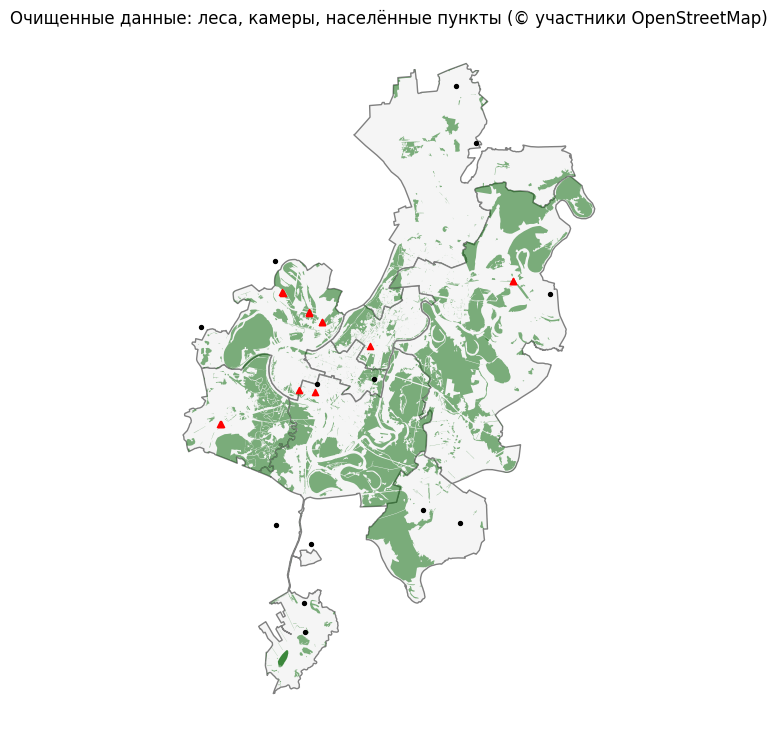

In [7]:
ax = clean["districts"].plot(figsize=(9, 9), color="whitesmoke", edgecolor="gray")
clean["forests"].plot(ax=ax, color="darkgreen", alpha=0.5)
clean["cameras"].plot(ax=ax, color="red", markersize=20, marker="^")
clean["settlements"].plot(ax=ax, color="black", markersize=8)
ax.set_title("Очищенные данные: леса, камеры, населённые пункты (© участники OpenStreetMap)")
ax.set_axis_off()

## Перенос результатов в репозиторий

Очищенные слои из `data/processed` должны попасть в репозиторий через Pull Request. В Colab ячейка ниже соберёт их в архив `results_02.zip` и скачает на компьютер. Распакуйте архив и загрузите файлы в те же папки репозитория в своей ветке: **Add file → Upload files** (подробно в приложении Б, шаг 6).

Файлы больше 10 МБ в репозиторий не загружайте: ячейка о них предупредит. При локальной работе результаты уже лежат в папках репозитория, ячейку можно пропустить.

In [8]:
import shutil
FOLDERS = [PROCESSED]
if IN_COLAB:
    from google.colab import files
    pack = Path("/content/results_02")
    shutil.rmtree(pack, ignore_errors=True)
    for folder in FOLDERS:
        for f in folder.rglob("*"):
            if f.is_file() and f.name != ".gitkeep":
                if f.stat().st_size > 10 * 1024 * 1024:
                    print(f"Пропущен (больше 10 МБ): {f.relative_to(BASE)}")
                    continue
                target = pack / f.relative_to(BASE)
                target.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(f, target)
    archive = shutil.make_archive(str(pack), "zip", pack)
    print("В архиве:", sorted(str(p.relative_to(pack)) for p in pack.rglob("*") if p.is_file()))
    files.download(archive)
else:
    print("Локальный запуск: результаты уже лежат в папках репозитория")

В архиве: ['data/processed/boundary.gpkg', 'data/processed/cameras.gpkg', 'data/processed/districts.gpkg', 'data/processed/forests.gpkg', 'data/processed/profile_summary.csv', 'data/processed/settlements.gpkg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Выводы (заполните)

- Пригодны ли данные для ответа на каждый аналитический вопрос?

Для первого вопроса — площади лесного фонда вне зоны покрытия камер — данных достаточно с оговорками: леса и камеры есть, но полнота слоя камер неизвестна, поэтому площадь «слепых зон» завышена, и оценка покрытия является нижней границей. Для второго вопроса — доли пожаров в слепых зонах — данных недостаточно, потому что нет слоя исторических пожаров. Для третьего вопроса — обучения модуля верификации — данных тоже недостаточно: нет ни спутниковых данных, ни размеченных случаев. Итог: для вопроса 1 достаточно с оговорками, для вопросов 2–3 недостаточно; MVP стоит сузить до анализа слепых зон, а исторические пожары и спутник вынести в критичные задачи на ЛР 3.
- Какие проблемы найдены и какие задачи заведены (номера Issues)?

Камер в OSM мало (13 против десятков реальных) — заведена задача запросить у Минлесхоза перечень камер «Лесохранитель» (Must). Нет исторических данных о пожарах — задача найти открытые данные по РБ (Must). Восемь из тринадцати камер стоят ближе 50 м друг к другу — задача проверить пары вручную на возможные дубликаты (Should). У четырёх камер не указан surveillance:type — задача проверить их на карте и исключить нецелевые (Should). Колонки operator нет ни у одной камеры — задача запросить у заказчика данные операторов связи (Should). Площадь границы города требует проверки (должна быть около 708 км²) — задача проверить площадь и при расхождении перезагрузить ноутбук 01 с bbox города (Must).
- Какие правила очистки применены и согласованы ли они с заказчиком?

Применены: make_valid для устранения самопересечений, удаление дубликатов по (osm_type, osm_id), приведение settlements и cameras к точкам через representative_point, обрезка forests по границе города через overlay, порог дубликатов камер 50 м вместо 5 м. Правила 1–3 и 5 согласованы с командой и не меняют смысл данных. Правило 4 (обрезка лесов) требует подтверждения заказчика и проверки площади границы — до этого выводы о площади леса считать предварительными.

Перенесите выводы в `docs/data-quality.md`.